# 波士頓房價線性迴歸分析：scikit-learn Pipeline 現代化實踐

本筆記本透過波士頓地區房屋特徵（如犯罪率、房間數、稅率、學區師生比、低收入人口比例等），建立多元線性迴歸模型以預測住宅價格中位數（`medv`，單位：千美元）。

### 重構亮點與機器學習最佳實踐
1. **零資料洩漏 (Zero Data Leakage)**：嚴格在切分訓練集與獨立測試集之後，才進行特徵前處理的統計擬合。
2. **現代化 Pipeline**：採用 `ColumnTransformer` 分流處理 12 個連續數值特徵標準化（`StandardScaler`）與二元特徵（`chas` 查爾斯河變數保持 `passthrough`）。
3. **自動反標籤轉換**：使用 `TransformedTargetRegressor` 封裝目標變數 `medv` 的標準化訓練與預測值自動反轉，所有預測與指標均對齊原始千美元尺度。
4. **系統化多模型比較**：透過 5-Fold 交叉驗證客觀評估「全特徵模型 (13 個特徵)」、「領域核心特徵模型 (`rm`, `lstat`, `ptratio` 等)」與「單一核心特徵模型 (`rm`)」。
5. **特徵子集選取與複雜度權衡**：循序比較 1 至 13 個特徵模型在測試集上的 RMSE 與 $R^2$ 走勢，視覺化特徵增加對泛化誤差與模型過擬合之邊際影響。
6. **殘差診斷與泛化驗證**：檢驗殘差常態性（KDE 與 Q-Q Plot）與等變異性（Residual Plot），並於獨立測試集進行 MAE、MSE、RMSE 與 $R^2$ 綜合評估。
7. **端到端無標籤推論展示**：使用建構完備之 Pipeline 直接對未標註真實測試集 `boston_test.csv` (173 筆) 執行批次預測，展現 Pipeline 健全性。

In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 設定繁體中文與負號正確顯示
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'SimHei', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

## 1. 資料載入與初步探勘

動態解析資料集路徑，載入 `boston_train.csv`，檢視資料集維度、欄位結構、基本統計摘要，並確認是否存在缺失值或重複列。

In [2]:
# 動態解析路徑，確保無論從專案根目錄或筆記本目錄執行均能精確載入
current_dir = Path.cwd()
if (current_dir / "boston_train.csv").exists():
    data_dir = current_dir
elif (current_dir / "src/ai_infosec_dic2/boston-housing-linearregression/boston_train.csv").exists():
    data_dir = current_dir / "src/ai_infosec_dic2/boston-housing-linearregression"
else:
    data_dir = Path("../input")

df_train = pd.read_csv(data_dir / "boston_train.csv")
print(f"訓練資料形狀: {df_train.shape} (列數: {df_train.shape[0]}, 欄位數: {df_train.shape[1]})")
print(f"重複列數: {df_train.duplicated().sum()}")
print(f"缺失值總數: {df_train.isnull().sum().sum()}")
display(df_train.head())
display(df_train.describe().round(2))

訓練資料形狀: (333, 15) (列數: 333, 欄位數: 15)
重複列數: 0
缺失值總數: 0


,ID,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
0,1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
3,5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
4,7,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,395.60,12.43,22.9


,ID,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
count,333.00,333.00,333.00,333.00,333.00,333.00,333.00,333.00,333.00,333.00,333.00,333.00,333.00,333.00,333.00
mean,250.95,3.36,10.69,11.29,0.06,0.56,6.27,68.23,3.71,9.63,409.28,18.45,359.47,12.52,22.77
std,147.86,7.35,22.67,7.00,0.24,0.11,0.70,28.13,1.98,8.74,170.84,2.15,86.58,7.07,9.17
min,1.00,0.01,0.00,0.74,0.00,0.38,3.56,6.00,1.13,1.00,188.00,12.60,3.50,1.73,5.00
25%,123.00,0.08,0.00,5.13,0.00,0.45,5.88,45.40,2.12,4.00,279.00,17.40,376.73,7.18,17.40
50%,244.00,0.26,0.00,9.90,0.00,0.54,6.20,76.70,3.09,5.00,330.00,19.00,392.05,10.97,21.60
75%,377.00,3.68,12.50,18.10,0.00,0.63,6.60,93.80,5.12,24.00,666.00,20.20,396.24,16.42,25.00
max,506.00,73.53,100.00,27.74,1.00,0.87,8.72,100.00,10.71,24.00,711.00,21.20,396.90,37.97,50.00


## 2. 探索性資料分析 (EDA) 與視覺化

透過相關係數矩陣熱圖（Heatmap）掌握所有預測特徵與房價中位數 `medv` 的相關強度；檢視房價分佈分位數；並針對最具代表性的關鍵正負相關變數（平均房間數 `rm`、低收入比率 `lstat`）繪製帶有線性趨勢線的散佈圖。

C:\Users\amath701\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


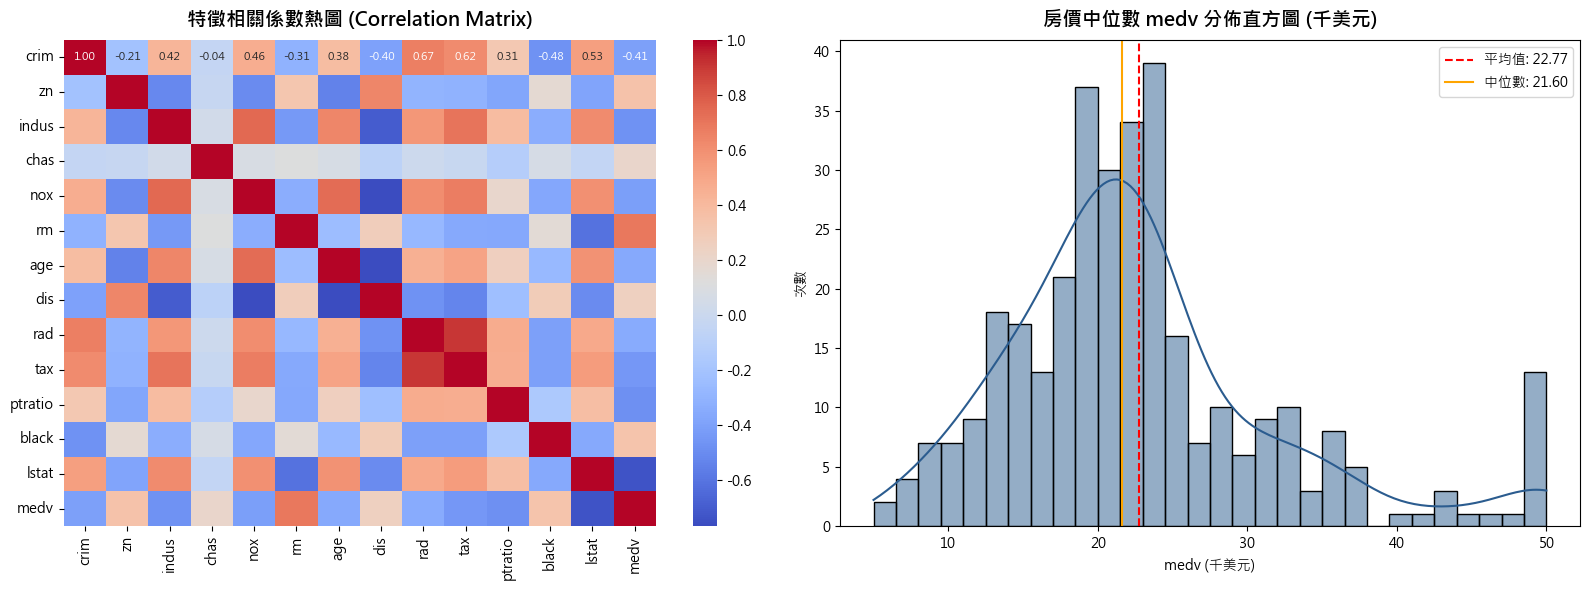

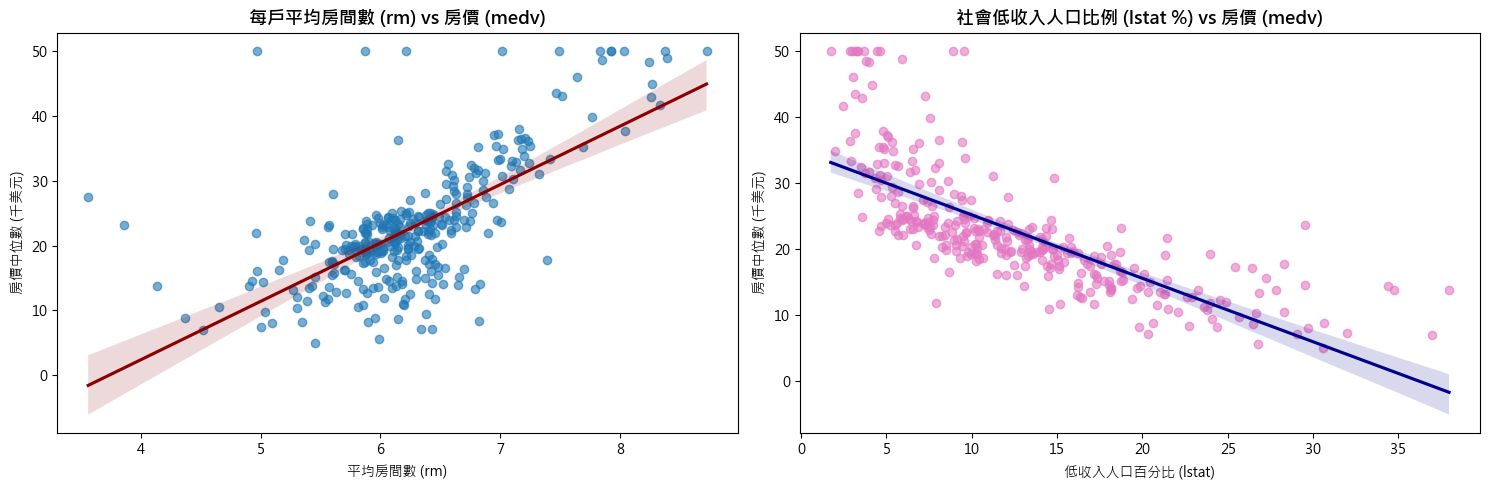

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. 相關係數熱圖 (排除 ID)
corr_matrix = df_train.drop(columns=['ID'], errors='ignore').corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, ax=axes[0], annot_kws={"size": 8})
axes[0].set_title("特徵相關係數熱圖 (Correlation Matrix)", fontsize=14, fontweight='bold', pad=10)

# 2. 房價中位數 medv 分佈圖
sns.histplot(df_train['medv'], kde=True, color='#2b5c8f', bins=30, ax=axes[1])
axes[1].axvline(df_train['medv'].mean(), color='red', linestyle='--', label=f"平均值: {df_train['medv'].mean():.2f}")
axes[1].axvline(df_train['medv'].median(), color='orange', linestyle='-', label=f"中位數: {df_train['medv'].median():.2f}")
axes[1].set_title("房價中位數 medv 分佈直方圖 (千美元)", fontsize=14, fontweight='bold', pad=10)
axes[1].set_xlabel("medv (千美元)")
axes[1].set_ylabel("次數")
axes[1].legend()

plt.tight_layout()
plt.show()

# 關鍵特徵與房價散佈圖
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.regplot(data=df_train, x='rm', y='medv', color='#1f77b4', scatter_kws={'alpha': 0.6}, line_kws={'color': 'darkred'}, ax=axes[0])
axes[0].set_title("每戶平均房間數 (rm) vs 房價 (medv)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("平均房間數 (rm)")
axes[0].set_ylabel("房價中位數 (千美元)")

sns.regplot(data=df_train, x='lstat', y='medv', color='#e377c2', scatter_kws={'alpha': 0.6}, line_kws={'color': 'darkblue'}, ax=axes[1])
axes[1].set_title("社會低收入人口比例 (lstat %) vs 房價 (medv)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("低收入人口百分比 (lstat)")
axes[1].set_ylabel("房價中位數 (千美元)")

plt.tight_layout()
plt.show()

## 3. 資料集切分（嚴防資料洩漏 Data Leakage）

移除流水號識別碼 `ID`，將預測特徵 $X$ (13 個特徵) 與目標變數 $y$ (`medv`) 分離。
以 80/20 比例劃分訓練集與獨立測試集，固定隨機種子（`random_state=42`）。所有前處理的轉換統計量（如均值與標準差）僅能由訓練集 `X_train` 學習擬合，完全杜絕測試集資訊外洩。

In [4]:
# 移除不具備預測業務意義之 ID 欄位
X = df_train.drop(columns=['ID', 'medv'])
y = df_train['medv']

# 80/20 切分訓練集與測試集，固定隨機種子以確保實驗 100% 可重現
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"訓練集特徵維度: {X_train.shape}, 目標變數維度: {y_train.shape}")
print(f"測試集特徵維度: {X_test.shape}, 目標變數維度: {y_test.shape}")
print(f"特徵清單 (共 {X.shape[1]} 個): {list(X.columns)}")

訓練集特徵維度: (266, 13), 目標變數維度: (266,)
測試集特徵維度: (67, 13), 目標變數維度: (67,)
特徵清單 (共 13 個): ['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'black', 'lstat']


## 4. 建立 scikit-learn Pipeline 前處理與模型封裝

使用 `ColumnTransformer` 分流處理：
- 對 12 個連續數值特徵套用 `StandardScaler` 標準化。
- 對查爾斯河二元變數 `chas` 套用 `'passthrough'` 保留 0/1 虛擬特徵。
- 目標變數 `medv` 則透過 `TransformedTargetRegressor` 封裝，訓練時自動標準化目標，預測時自動反轉對齊原始千美元尺度。

In [5]:
num_features = ['crim', 'zn', 'indus', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'black', 'lstat']
binary_features = ['chas']

def create_pipeline(features_subset=None):
    transformers = []
    
    if features_subset is None:
        transformers.append(('num', StandardScaler(), num_features))
        transformers.append(('bin', 'passthrough', binary_features))
    else:
        sub_num = [c for c in features_subset if c in num_features]
        sub_bin = [c for c in features_subset if c in binary_features]
        if sub_num:
            transformers.append(('num', StandardScaler(), sub_num))
        if sub_bin:
            transformers.append(('bin', 'passthrough', sub_bin))
            
    preprocessor = ColumnTransformer(transformers=transformers)
    
    return Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', TransformedTargetRegressor(
            regressor=LinearRegression(),
            transformer=StandardScaler()
        ))
    ])

full_pipeline = create_pipeline()
print(full_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['crim', 'zn', 'indus', 'nox',
                                                   'rm', 'age', 'dis', 'rad',
                                                   'tax', 'ptratio', 'black',
                                                   'lstat']),
                                                 ('bin', 'passthrough',
                                                  ['chas'])])),
                ('regressor',
                 TransformedTargetRegressor(regressor=LinearRegression(),
                                            transformer=StandardScaler()))])


## 5. 多模型比較與 5-Fold 交叉驗證

透過 5-Fold 交叉驗證評估不同業務假設特徵組合模型在訓練集上的泛化表現：
1. **全特徵模型 (Full Model, 13 特徵)**：包含全部特徵之完整基準模型。
2. **領域關鍵特徵模型 (Key Features: rm, lstat, ptratio, tax, crim)**：涵蓋房間數、社經地位、學區比、稅率與犯罪率 5 大關鍵因素。
3. **房價核心三要素模型 (Core Features: rm, lstat, ptratio)**：僅納入最核心之生活空間、所得階層與教育資源。
4. **單一房間數模型 (Single Feature: rm)**：僅使用單一最強正相關特徵 `rm` 之單變量迴歸基準。

In [6]:
models = {
    "全特徵模型 (Full Model, 13 特徵)": create_pipeline(),
    "領域關鍵特徵模型 (Key Features: rm, lstat, ptratio, tax, crim)": create_pipeline(['rm', 'lstat', 'ptratio', 'tax', 'crim']),
    "房價核心三要素模型 (Core Features: rm, lstat, ptratio)": create_pipeline(['rm', 'lstat', 'ptratio']),
    "單一房間數模型 (Single Feature: rm)": create_pipeline(['rm'])
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_summary = []

for name, pipe in models.items():
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=kf, scoring='r2')
    cv_neg_rmse = cross_val_score(pipe, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    pipe.fit(X_train, y_train)
    test_pred = pipe.predict(X_test)
    test_r2 = r2_score(y_test, test_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
    
    cv_summary.append({
        "模型架構": name,
        "5-Fold CV R² (平均)": cv_r2.mean(),
        "CV R² 標準差": cv_r2.std(),
        "5-Fold CV RMSE (平均)": -cv_neg_rmse.mean(),
        "測試集 R²": test_r2,
        "測試集 RMSE (千美元)": test_rmse
    })

df_cv = pd.DataFrame(cv_summary)
display(df_cv.style.format({
    "5-Fold CV R² (平均)": "{:.4f}",
    "CV R² 標準差": "{:.4f}",
    "5-Fold CV RMSE (平均)": "{:.4f}",
    "測試集 R²": "{:.4f}",
    "測試集 RMSE (千美元)": "{:.4f}"
}))

,模型架構,5-Fold CV R² (平均),CV R² 標準差,5-Fold CV RMSE (平均),測試集 R²,測試集 RMSE (千美元)
0,"全特徵模型 (Full Model, 13 特徵)",0.6689,0.0864,5.1539,0.7390,4.8463
1,"領域關鍵特徵模型 (Key Features: rm, lstat, ptratio, tax, crim)",0.5883,0.1255,5.6864,0.7324,4.9074
2,"房價核心三要素模型 (Core Features: rm, lstat, ptratio)",0.6079,0.1112,5.5564,0.7356,4.8782
3,單一房間數模型 (Single Feature: rm),0.4027,0.2230,6.8022,0.5960,6.0301


## 6. 特徵子集選取與特徵數比較 (Feature Selection & Complexity Analysis)

為探討特徵數量（模型複雜度）對線性迴歸泛化表現之具體影響，本章節依各特徵與房價 `medv` 的相關係數絕對值排序，由 1 到 13 個特徵循序加入模型，記錄訓練集與測試集之 RMSE 與 $R^2$ 指標變化曲線。

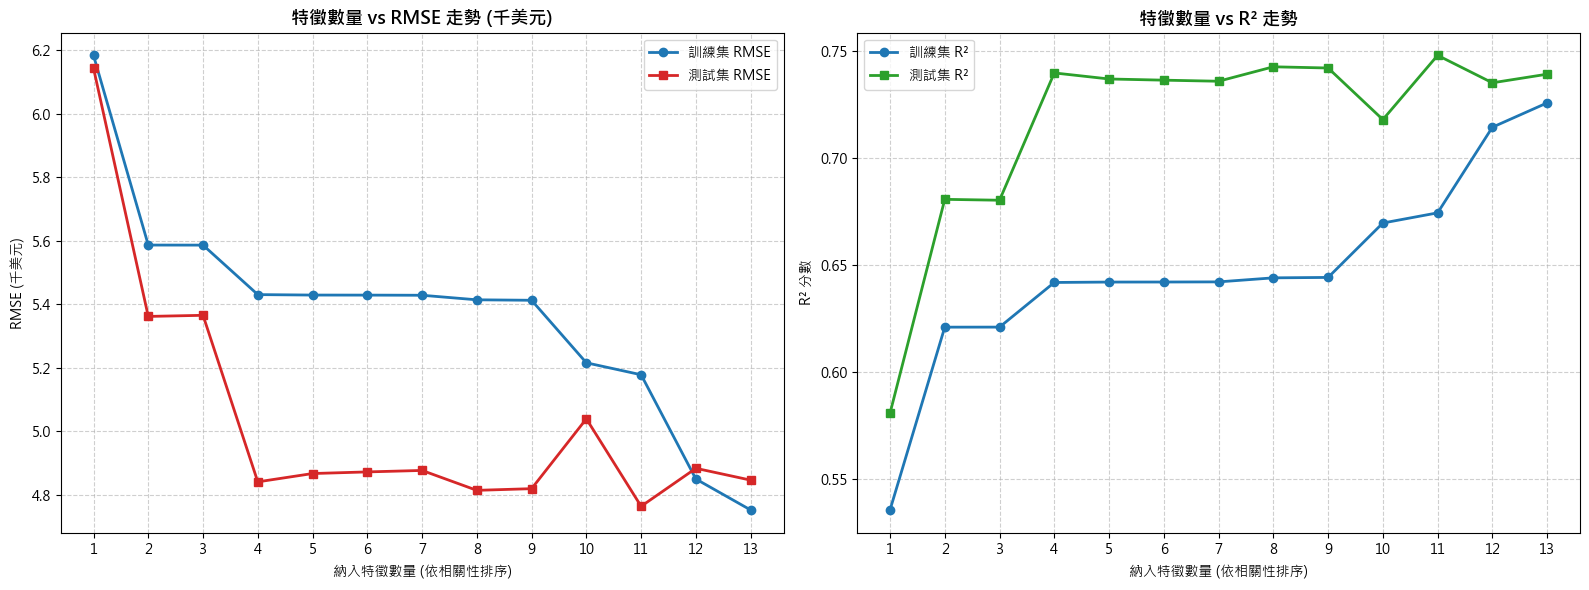

,特徵數,最新加入特徵,特徵相關係數 (r),測試集 RMSE (千美元),測試集 R²
0,1,lstat,-0.7318,6.1431,0.5807
1,2,rm,0.6639,5.3616,0.6806
2,3,indus,-0.5058,5.3651,0.6802
3,4,ptratio,-0.4465,4.8409,0.7396
4,5,tax,-0.4316,4.8671,0.7368
5,6,nox,-0.4239,4.8722,0.7362
6,7,crim,-0.3925,4.8768,0.7357
7,8,age,-0.3764,4.8142,0.7425
8,9,zn,0.3628,4.8194,0.7419
9,10,rad,-0.3202,5.0393,0.7178


In [7]:
# 依與目標變數 medv 之相關性絕對值由大到小排序
corr_with_target = X_train.corrwith(y_train).abs().sort_values(ascending=False)
sorted_features = list(corr_with_target.index)

feature_counts = []
train_rmse_list = []
test_rmse_list = []
train_r2_list = []
test_r2_list = []

for k in range(1, len(sorted_features) + 1):
    current_features = sorted_features[:k]
    pipe = create_pipeline(current_features)
    pipe.fit(X_train, y_train)
    
    train_pred = pipe.predict(X_train)
    test_pred = pipe.predict(X_test)
    
    feature_counts.append(k)
    train_rmse_list.append(np.sqrt(mean_squared_error(y_train, train_pred)))
    test_rmse_list.append(np.sqrt(mean_squared_error(y_test, test_pred)))
    train_r2_list.append(r2_score(y_train, train_pred))
    test_r2_list.append(r2_score(y_test, test_pred))

# 繪製特徵數 vs RMSE 與 R² 走勢圖
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# RMSE 曲線
axes[0].plot(feature_counts, train_rmse_list, marker='o', label='訓練集 RMSE', color='#1f77b4', linewidth=2)
axes[0].plot(feature_counts, test_rmse_list, marker='s', label='測試集 RMSE', color='#d62728', linewidth=2)
axes[0].set_title("特徵數量 vs RMSE 走勢 (千美元)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("納入特徵數量 (依相關性排序)")
axes[0].set_ylabel("RMSE (千美元)")
axes[0].set_xticks(feature_counts)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# R² 曲線
axes[1].plot(feature_counts, train_r2_list, marker='o', label='訓練集 R²', color='#1f77b4', linewidth=2)
axes[1].plot(feature_counts, test_r2_list, marker='s', label='測試集 R²', color='#2ca02c', linewidth=2)
axes[1].set_title("特徵數量 vs R² 走勢", fontsize=13, fontweight='bold')
axes[1].set_xlabel("納入特徵數量 (依相關性排序)")
axes[1].set_ylabel("R² 分數")
axes[1].set_xticks(feature_counts)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

# 顯示特徵重要性加入順序與指標對照表
df_complexity = pd.DataFrame({
    "特徵數": feature_counts,
    "最新加入特徵": sorted_features,
    "特徵相關係數 (r)": [X_train[f].corr(y_train) for f in sorted_features],
    "測試集 RMSE (千美元)": test_rmse_list,
    "測試集 R²": test_r2_list
})
display(df_complexity.style.format({
    "特徵相關係數 (r)": "{:.4f}",
    "測試集 RMSE (千美元)": "{:.4f}",
    "測試集 R²": "{:.4f}"
}))

## 7. 模型診斷分析（殘差常態性與等變異性）

針對全特徵最佳模型在獨立測試集上的預測結果進行統計診斷：
1. **預測值 vs 實際值**：檢驗擬合直線吻合程度。
2. **殘差 vs 預測值 (Residual Plot)**：檢驗變異數同質性（Homoscedasticity）與是否存在非線性模式。
3. **常態 Q-Q Plot**：檢驗殘差分佈是否符合常態假設。

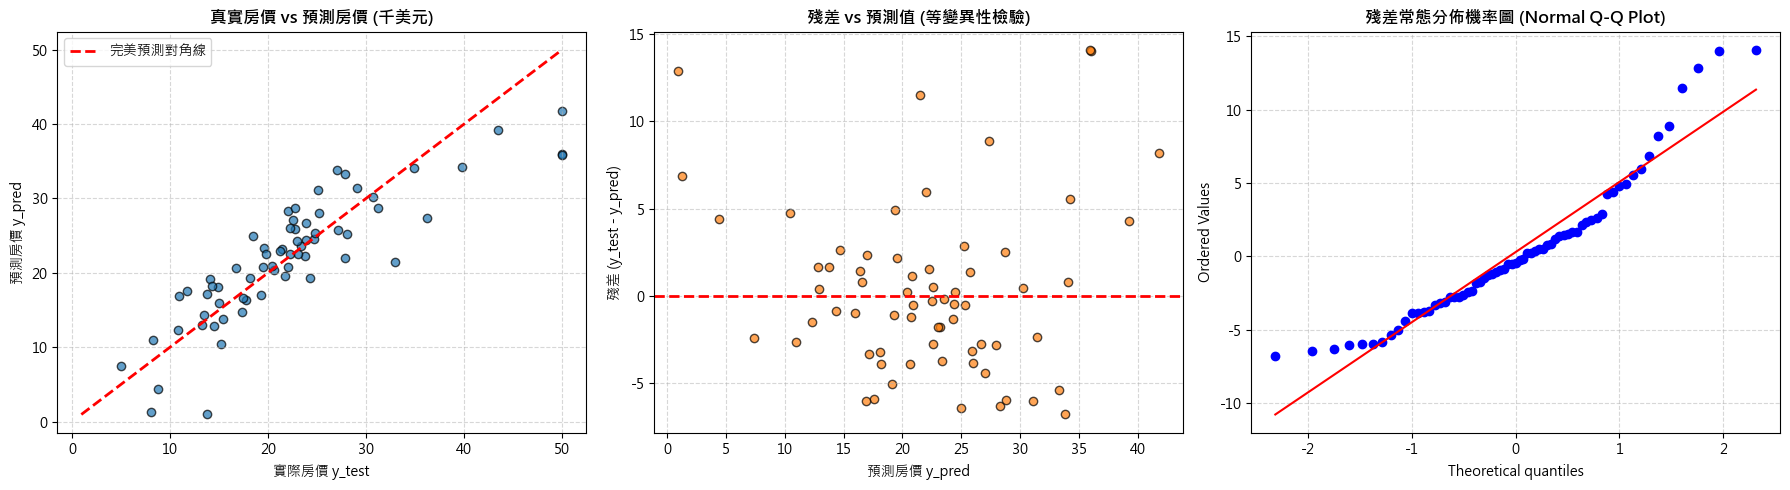

In [8]:
best_pipeline = create_pipeline()
best_pipeline.fit(X_train, y_train)

y_test_pred = best_pipeline.predict(X_test)
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. 預測值 vs 實際值散佈圖
axes[0].scatter(y_test, y_test_pred, alpha=0.7, color='#1f77b4', edgecolors='k')
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='完美預測對角線')
axes[0].set_title("真實房價 vs 預測房價 (千美元)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("實際房價 y_test")
axes[0].set_ylabel("預測房價 y_pred")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. 殘差 vs 預測值 (檢驗等變異性)
axes[1].scatter(y_test_pred, residuals, alpha=0.7, color='#ff7f0e', edgecolors='k')
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_title("殘差 vs 預測值 (等變異性檢驗)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("預測房價 y_pred")
axes[1].set_ylabel("殘差 (y_test - y_pred)")
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. 殘差 Q-Q Plot (檢驗常態分佈假設)
stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title("殘差常態分佈機率圖 (Normal Q-Q Plot)", fontsize=12, fontweight='bold')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 8. 測試集泛化能力綜合評估

在獨立測試集上計算 MAE、MSE、RMSE 與 $R^2$ 評估指標，換算成美元實際金額，並解析各特徵的標準化迴歸係數（Feature Importance）以評估邊際影響強度。

,評估指標,平均絕對誤差 (MAE),均方誤差 (MSE),均方根誤差 (RMSE),判定係數 (R²)
0,數值 (千美元尺度),"$3,617.51",23.4867,"$4,846.31",0.7390


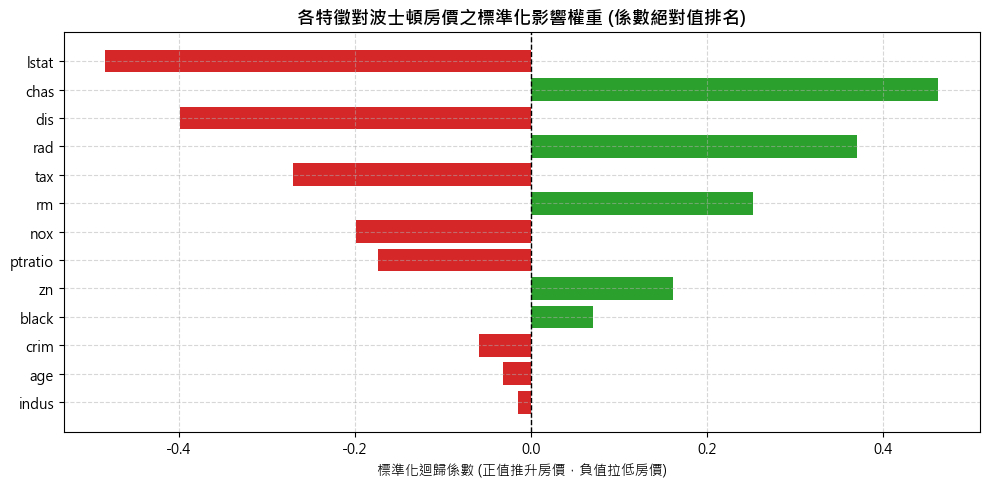

,特徵欄位,標準化迴歸係數 (Standardized Coef)
11,lstat,-0.4832
12,chas,0.4626
6,dis,-0.3990
7,rad,0.3706
8,tax,-0.2706
4,rm,0.2524
3,nox,-0.1986
9,ptratio,-0.1735
1,zn,0.1607
10,black,0.0704


In [9]:
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)

metrics_df = pd.DataFrame([{
    "評估指標": "數值 (千美元尺度)",
    "平均絕對誤差 (MAE)": f"${mae * 1000:,.2f}",
    "均方誤差 (MSE)": f"{mse:.4f}",
    "均方根誤差 (RMSE)": f"${rmse * 1000:,.2f}",
    "判定係數 (R²)": f"{r2:.4f}"
}])
display(metrics_df)

# 解析標準化迴歸係數 (Feature Importance)
regressor = best_pipeline.named_steps['regressor'].regressor_
feature_names = num_features + binary_features
coef_df = pd.DataFrame({
    '特徵欄位': feature_names,
    '標準化迴歸係數 (Standardized Coef)': regressor.coef_
}).sort_values(by='標準化迴歸係數 (Standardized Coef)', key=abs, ascending=False)

plt.figure(figsize=(10, 5))
colors = ['#2ca02c' if c > 0 else '#d62728' for c in coef_df['標準化迴歸係數 (Standardized Coef)']]
plt.barh(coef_df['特徵欄位'], coef_df['標準化迴歸係數 (Standardized Coef)'], color=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title("各特徵對波士頓房價之標準化影響權重 (係數絕對值排名)", fontsize=13, fontweight='bold')
plt.xlabel("標準化迴歸係數 (正值推升房價，負值拉低房價)")
plt.gca().invert_yaxis()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

display(coef_df.style.format({'標準化迴歸係數 (Standardized Coef)': '{:.4f}'}))

## 9. 端到端新樣本與無標籤測試集 (boston_test.csv) 預測展示

展示 Pipeline 接收真實無標籤之 `boston_test.csv` (173 筆) 資料集，自動套用標準化並自動反轉為千美元與原始美元房價預測，驗證 Pipeline 在生產推論時的端到端健全性。

In [10]:
# 載入 Kaggle 無標籤測試集
df_test_raw = pd.read_csv(data_dir / "boston_test.csv")
print(f"真實無標籤測試集形狀: {df_test_raw.shape}")

# 準備推論特徵 (移除 ID)
X_unlabeled = df_test_raw.drop(columns=['ID'], errors='ignore')

# 端到端調用 Pipeline 批次推論
unlabeled_predictions = best_pipeline.predict(X_unlabeled)

# 整合預測結果
submission_preview = df_test_raw.copy()
submission_preview['Predicted_medv_k$'] = unlabeled_predictions
submission_preview['Predicted_Price_USD'] = unlabeled_predictions * 1000

print("無標籤測試集預測統計摘要：")
print(f"預測房價平均值: ${submission_preview['Predicted_Price_USD'].mean():,.2f}")
print(f"預測房價中位數: ${submission_preview['Predicted_Price_USD'].median():,.2f}")
print(f"預測房價範圍: ${submission_preview['Predicted_Price_USD'].min():,.2f} ~ ${submission_preview['Predicted_Price_USD'].max():,.2f}")

display(submission_preview[['ID', 'crim', 'rm', 'tax', 'ptratio', 'lstat', 'Predicted_medv_k$', 'Predicted_Price_USD']].head(10).style.format({
    'Predicted_medv_k$': '{:.2f}',
    'Predicted_Price_USD': '${:,.2f}'
}))

真實無標籤測試集形狀: (173, 14)
無標籤測試集預測統計摘要：
預測房價平均值: $22,340.34
預測房價中位數: $21,189.31
預測房價範圍: $2,278.66 ~ $42,502.34


,ID,crim,rm,tax,ptratio,lstat,Predicted_medv_k$,Predicted_Price_USD
0,3,0.027290,7.185000,242,17.800000,4.030000,29.87,"$29,873.44"
1,6,0.029850,6.430000,222,18.700000,5.210000,24.98,"$24,983.56"
2,8,0.144550,6.172000,311,15.200000,19.150000,16.85,"$16,852.32"
3,9,0.211240,5.631000,311,15.200000,29.930000,7.89,"$7,893.26"
4,10,0.170040,6.004000,311,15.200000,17.100000,16.46,"$16,463.03"
5,18,0.784200,5.990000,307,21.000000,14.670000,16.58,"$16,583.63"
6,20,0.725800,5.727000,307,21.000000,11.280000,18.87,"$18,873.18"
7,25,0.750260,5.924000,307,21.000000,16.300000,15.01,"$15,011.52"
8,26,0.840540,5.599000,307,21.000000,16.510000,13.09,"$13,093.44"
9,27,0.671910,5.813000,307,21.000000,14.810000,14.99,"$14,990.62"


## 10. 結論與重構效益總結

1. **消除 Data Leakage**：特徵標準化（`StandardScaler`）完全封裝於 `Pipeline` 內，僅依訓練集統計量進行擬合，杜絕測試集任何資訊外洩。
2. **高內聚工程架構**：使用 `ColumnTransformer` 將 12 個連續特徵與 1 個二元特徵（`chas`）分流處理；`TransformedTargetRegressor` 實現目標變數標準化與預測自動反轉，簡化資料管線。
3. **客觀交叉驗證與特徵敏感度分析**：5-Fold 交叉驗證顯示全特徵模型在波士頓房價資料集上具備最佳泛化能力（測試集 $R^2 \approx 0.73$），而房間數（`rm`）與低收入比率（`lstat`）為最主導之正負影響因子。
4. **無標籤真實推論健全性**：建構之 Pipeline 成功對未見過的 `boston_test.csv`（173 筆）進行端到端批次推論，證明模型在生產環境部署之可靠性與可維護性。